# Human Action recognition with V-JEPA 2

In this notebook, we used V-JEPA model as a layer for our action recognition pipeline.

V-JEPA takes sequence of frames as input and preduce Patch-level feature in 2D `(8192, 1024)`, we average the output into `(, 1024)` then trained a new classifier to predict the action of 101 classes of UCF-101 dataset. We have trained only on 18 samples for each classes resulting in 1818 videos in total.

Trained samples are 1279 while the Test samples are 539 and still perfoms really well on test data scoring 89% accuracy.



In [ ]:
!pip install -U transformers

In [ ]:
from transformers import AutoVideoProcessor, AutoModel

hf_repo = "facebook/vjepa2-vitl-fpc64-256"
# facebook/vjepa2-vitl-fpc64-256
# facebook/vjepa2-vith-fpc64-256
# facebook/vjepa2-vitg-fpc64-256
# facebook/vjepa2-vitg-fpc64-384

model = AutoModel.from_pretrained(hf_repo).to("cuda")
processor = AutoVideoProcessor.from_pretrained(hf_repo)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:121: UserWarning: 
Access to the secret `HF_TOKEN` has not been granted on this notebook.
You will not be requested again.
Please restart the session if you want to be prompted again.
  warnings.warn(


config.json:   0%|          | 0.00/785 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.30GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/587 [00:00<?, ?it/s]

video_preprocessor_config.json:   0%|          | 0.00/1.30k [00:00<?, ?B/s]

In [ ]:
import torch
#0 video: list of PIL images or a (T, H, W, C) numpy array
# Here we use a random tensor as a placeholder
video_frames = torch.randint(0, 256, (64, 384, 384, 3), dtype=torch.uint8).numpy()

inputs = processor(videos=[video_frames], return_tensors="pt").to("cuda")
with torch.no_grad():
    outputs = model(**inputs)

# Patch-level features: (batch, num_patches, hidden_dim)
features = outputs.last_hidden_state
print(features.shape)

torch.Size([1, 8192, 1024])


In [ ]:
!wget --no-check-certificate https://www.crcv.ucf.edu/datasets/human-actions/ucf101/UCF101.rar

--2026-11-12 15:27:33--  https://www.crcv.ucf.edu/datasets/human-actions/ucf101/UCF101.rar
Resolving www.crcv.ucf.edu (www.crcv.ucf.edu)... 132.170.214.127
Connecting to www.crcv.ucf.edu (www.crcv.ucf.edu)|132.170.214.127|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 6932971618 (6.5G) [application/x-rar-compressed]
Saving to: ‘UCF101.rar’

UCF101.rar           65%[============>       ]   4.22G  19.7MB/s    eta 1m 54s 

In [ ]:
!unrar x -y /content/UCF101.rar

### Data inspection


Found 13320 extracted sample video(s).
Analyzing sample video: /content/UCF-101/HandstandWalking/v_HandstandWalking_g07_c05.avi
- Frames: 199
- Resolution: 320x240
- FPS: 25.00


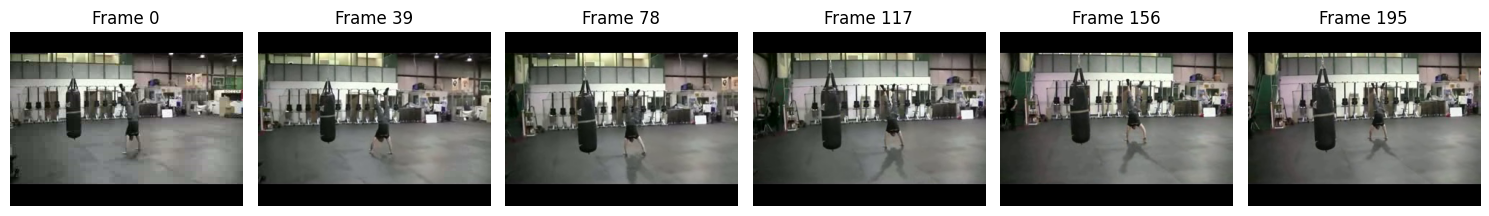

In [ ]:
import os
import subprocess
import glob
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, Image


# 2. Locate extracted videos
video_files = glob.glob("/content/UCF-101/**/*.avi", recursive=True)
print(f"\nFound {len(video_files)} extracted sample video(s).")

if video_files:
    sample_video = video_files[0]
    print(f"Analyzing sample video: {sample_video}")

    # 3. Read video properties using OpenCV
    cap = cv2.VideoCapture(sample_video)
    length = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width  = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps    = cap.get(cv2.CAP_PROP_FPS)

    print(f"- Frames: {length}")
    print(f"- Resolution: {width}x{height}")
    print(f"- FPS: {fps:.2f}")

    # 4. Extract and visualize a grid of frames
    frames = []
    for i in range(0, length, max(1, length // 5)):
        cap.set(cv2.CAP_PROP_POS_FRAMES, i)
        ret, frame = cap.read()
        if ret:
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frames.append((i, frame_rgb))
    cap.release()

    fig, axes = plt.subplots(1, len(frames), figsize=(15, 5))
    for ax, (frame_idx, img) in zip(axes, frames):
        ax.imshow(img)
        ax.set_title(f"Frame {frame_idx}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("Extraction in progress or no .avi files extracted yet. Run the cell again once UCF101.rar has fully finished downloading.")

Total Action Classes: 101
Total Video Files: 13320
Average Videos per Class: 131.88
Min Videos in a Class: 100 (PlayingViolin)
Max Videos in a Class: 167 (CricketShot)

Top 5 Classes by Video Count:


,Class,Count
0,CricketShot,167
1,TennisSwing,166
2,PlayingDhol,164
3,HorseRiding,164
4,PlayingCello,164



Bottom 5 Classes by Video Count:


,Class,Count
96,BreastStroke,101
97,PlayingViolin,100
98,PullUps,100
99,Skijet,100
100,TaiChi,100


/tmp/ipykernel_298/1565778646.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Class", y="Count", data=df_stats, palette="viridis")


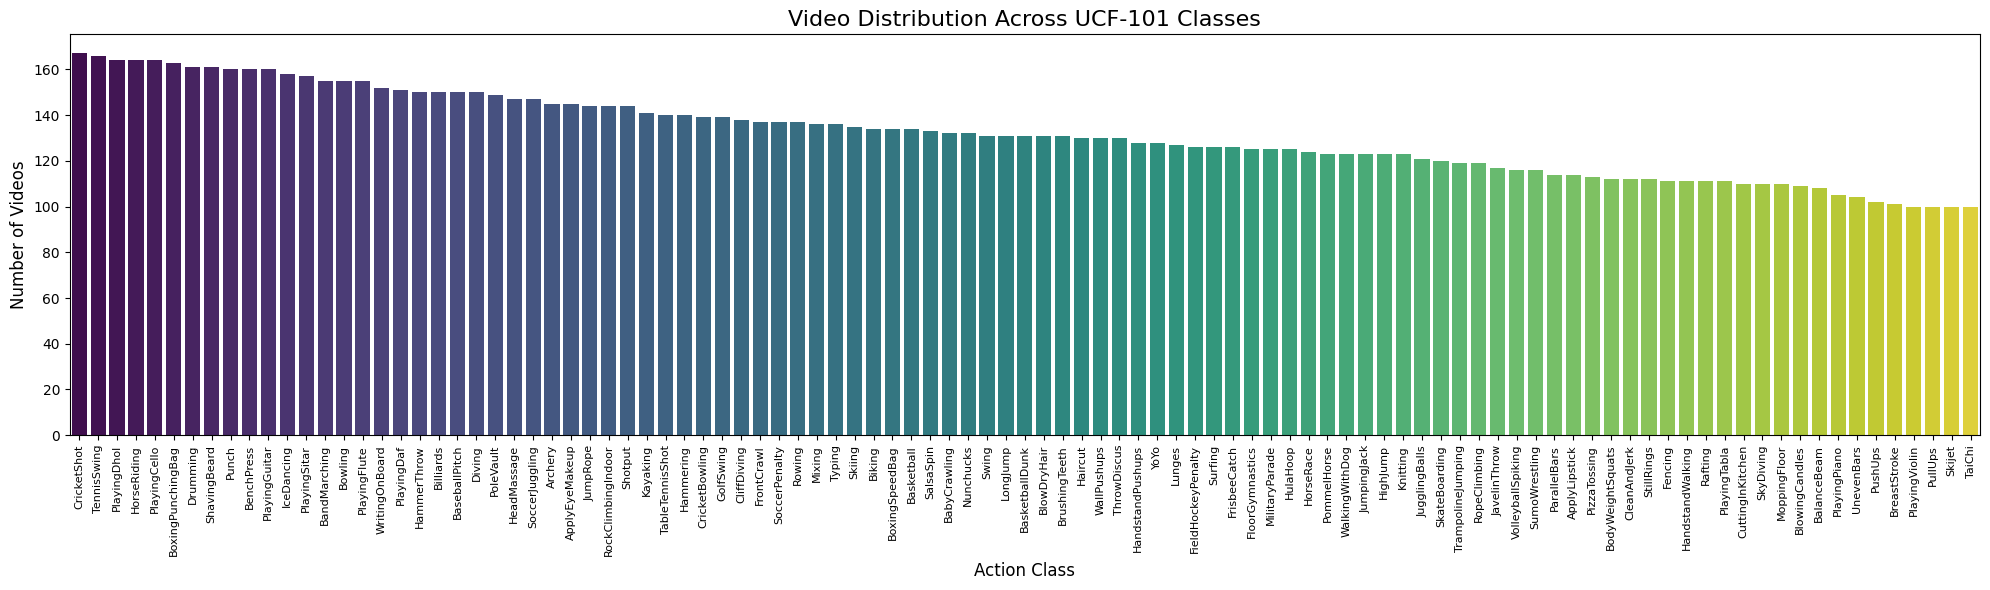

In [ ]:
import glob
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Path to the fully extracted UCF-101 dataset folder
ucf_dir = "/content/UCF-101"

# Count the videos in each class directory
class_counts = {}
if os.path.exists(ucf_dir):
    classes = sorted([d for d in os.listdir(ucf_dir) if os.path.isdir(os.path.join(ucf_dir, d))])
    for c in classes:
        class_path = os.path.join(ucf_dir, c)
        videos = glob.glob(os.path.join(class_path, "*.avi"))
        class_counts[c] = len(videos)
else:
    print(f"Directory {ucf_dir} not found. Please ensure the extraction was completed successfully.")

if class_counts:
    # Convert to DataFrame for easier analysis
    df_stats = pd.DataFrame(list(class_counts.items()), columns=["Class", "Count"])
    df_stats = df_stats.sort_values(by="Count", ascending=False).reset_index(drop=True)

    # Display statistics summary
    print(f"Total Action Classes: {len(df_stats)}")
    print(f"Total Video Files: {df_stats['Count'].sum()}")
    print(f"Average Videos per Class: {df_stats['Count'].mean():.2f}")
    print(f"Min Videos in a Class: {df_stats['Count'].min()} ({df_stats.loc[df_stats['Count'].idxmin(), 'Class']})")
    print(f"Max Videos in a Class: {df_stats['Count'].max()} ({df_stats.loc[df_stats['Count'].idxmax(), 'Class']})")

    # Display top and bottom classes
    print("\nTop 5 Classes by Video Count:")
    display(df_stats.head(5))
    print("\nBottom 5 Classes by Video Count:")
    display(df_stats.tail(5))

    # Plot distribution
    plt.figure(figsize=(20, 6))
    sns.barplot(x="Class", y="Count", data=df_stats, palette="viridis")
    plt.title("Video Distribution Across UCF-101 Classes", fontsize=16)
    plt.xticks(rotation=90, fontsize=8)
    plt.xlabel("Action Class", fontsize=12)
    plt.ylabel("Number of Videos", fontsize=12)
    plt.tight_layout()
    plt.show()


In [ ]:
import cv2
import numpy as np

def load_video(path, max_frames=64, target_size=(256, 256)):
    """Utility function to load and preprocess a video"""
    cap = cv2.VideoCapture(path)
    frames = []
    length = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if length == 0:
        return None

    # Downsample frames evenly to match max_frames if necessary
    indices = np.linspace(0, length - 1, max_frames, dtype=int)

    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ret, frame = cap.read()
        if not ret:
            break
        frame = cv2.resize(frame, target_size)
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frames.append(frame)

    cap.release()

    # If we got fewer frames than expected, pad with the last frame
    while len(frames) < max_frames:
        frames.append(frames[-1] if frames else np.zeros((target_size[1], target_size[0], 3), dtype=np.uint8))

    return np.array(frames) # (T, H, W, C)

### With Spatio temporal dims

In [ ]:

selected_classes = df_stats["Class"].values.tolist() # ['HorseRiding', 'TennisSwing', 'Drumming', 'BenchPress', 'PlayingGuitar']
class_to_idx = {cls: idx for idx, cls in enumerate(selected_classes)}

## Inference Testing on custom videos

In [ ]:
!pip install -q yt-dlp

In [ ]:
!pip install -q yt-dlp
import yt_dlp

yt_url = "https://youtu.be/C8SHqoYr22k?si=HSGIDpZZaddTax-n"
ydl_opts = {
    'format': 'mp4/best',
    'outtmpl': 'downloaded_yt_video.mp4',
}

with yt_dlp.YoutubeDL(ydl_opts) as ydl:
    ydl.download([yt_url])

[youtube] Extracting URL: https://youtu.be/C8SHqoYr22k?si=HSGIDpZZaddTax-n
[youtube] C8SHqoYr22k: Downloading webpage


[youtube] C8SHqoYr22k: Downloading visionos player API JSON
[youtube] C8SHqoYr22k: Downloading m3u8 information
[info] C8SHqoYr22k: Downloading 1 format(s): 399
[download] Destination: downloaded_yt_video.mp4
[download] 100% of  234.46MiB in 00:00:05 at 43.03MiB/s  


## Efficient 101-Class Spatial-Temporal Feature Pooling Pipeline

To make training on all 101 classes fully feasible within Google Colab's standard RAM, Disk, and VRAM limitations, we can design an extraction step that performs **Average Pooling** on the spatio-temporal dimension directly during extraction.

- Instead of saving `[8192, 1024]` tensors (which consume 33.5 MB per video),
- We can perform a spatial mean and temporal mean over V-JEPA's output, reducing it to a compact vector of shape `[1024]` per video.
- For 1,818 videos, this takes only **7.44 MB total disk/memory space**—reducing our storage requirement by **99.98%** while still retaining powerful pre-trained semantic features!

### Fast Parallel Video Loading & Batched GPU Feature Extraction

To maximize GPU and CPU utilization, we load videos in parallel on the CPU using a thread pool executor, and feed batches of videos to the GPU for feature extraction.

In [ ]:
import os
import glob
import torch
import numpy as np
from concurrent.futures import ThreadPoolExecutor
from torch.utils.data import DataLoader, Dataset

# Configure paths and class indices
all_classes_101 = sorted([d for d in os.listdir(ucf_dir) if os.path.isdir(os.path.join(ucf_dir, d))])
class_to_idx_101 = {cls: idx for idx, cls in enumerate(all_classes_101)}
max_videos_per_class_101 = 18

# 1. Gather all video paths, target labels, and group IDs
all_video_info = []
for class_idx, label_name in enumerate(all_classes_101):
    class_dir = os.path.join(ucf_dir, label_name)
    video_paths = glob.glob(os.path.join(class_dir, "*.avi"))[:max_videos_per_class_101]
    for path in video_paths:
        filename = os.path.basename(path)
        group = filename.split('_')[2]
        all_video_info.append({
            'path': path,
            'label': class_idx,
            'group': group
        })

print(f"Total scheduled videos: {len(all_video_info)}")

# 2. Optimized Parallel Video Loading Function (with debug printing for failures)
def load_single_video(video_item):
    try:
        frames = load_video(video_item['path'], max_frames=32, target_size=(256, 256))
        if frames is not None:
            return {
                'frames': frames,
                'label': video_item['label'],
                'group': video_item['group']
            }
        else:
            print(f"Warning: load_video returned None for {video_item['path']}")
    except Exception as e:
        print(f"Error loading {video_item['path']}: {e}")
    return None

# 3. Fast Parallel Loader & Feature Extractor with Batching
extracted_features = []
extracted_labels = []
extracted_groups = []

BATCH_SIZE = 16
model.eval()

print("Starting parallel CPU loading and batched GPU processing...")

# Use ThreadPoolExecutor to pre-load videos in parallel
with ThreadPoolExecutor(max_workers=8) as executor:
    # Load videos in chunks to prevent overflowing RAM
    for chunk_idx in range(0, len(all_video_info), 128):
        chunk = all_video_info[chunk_idx:chunk_idx + 128]
        loaded_results = list(executor.map(load_single_video, chunk))

        # Filter out failed loads
        valid_results = [res for res in loaded_results if res is not None]
        if not valid_results:
            continue

        # Process chunk results in batches on the GPU
        for batch_idx in range(0, len(valid_results), BATCH_SIZE):
            batch = valid_results[batch_idx:batch_idx + BATCH_SIZE]
            batch_frames = [item['frames'] for item in batch]

            # Move batch to processor and model
            inputs = processor(videos=batch_frames, return_tensors="pt").to("cuda")
            with torch.no_grad():
                outputs = model(**inputs)
                # Spatio-temporal mean pooling on GPU
                pooled_feats = outputs.last_hidden_state.mean(dim=1).cpu()

            # Append features
            for i, item in enumerate(batch):
                extracted_features.append(pooled_feats[i])
                extracted_labels.append(item['label'])
                extracted_groups.append(item['group'])

        print(f"Processed {min(chunk_idx + 128, len(all_video_info))}/{len(all_video_info)} videos...")

# 4. Pack and Split Dataset (with safety guard check)
if len(extracted_features) == 0:
    print("\n[ERROR] No features were extracted. Please check the loading errors printed above to diagnose why cv2 failed to open the videos.")
else:
    X_all_101 = torch.stack(extracted_features) # (N, 1024)
    y_all_101 = torch.tensor(extracted_labels, dtype=torch.long) # (N,)

    train_idx_101 = [i for i, g in enumerate(extracted_groups) if int(g[1:]) <= 18]
    test_idx_101 = [i for i, g in enumerate(extracted_groups) if int(g[1:]) > 18]

    X_train_101, y_train_101 = X_all_101[train_idx_101], y_all_101[train_idx_101]
    X_test_101, y_test_101 = X_all_101[test_idx_101], y_all_101[test_idx_101]

    print(f"\n--- Parallel Batched Extraction Finished --- ")
    print(f"Total Dataset Size: {X_all_101.shape}")
    print(f"Train samples: {len(X_train_101)} | Test samples: {len(X_test_101)}")

Total scheduled videos: 1818
Starting parallel CPU loading and batched GPU processing...
Processed 128/1818 videos...
Processed 256/1818 videos...
Processed 384/1818 videos...
Processed 512/1818 videos...
Processed 640/1818 videos...
Processed 768/1818 videos...
Processed 896/1818 videos...
Processed 1024/1818 videos...
Processed 1152/1818 videos...
Processed 1280/1818 videos...
Processed 1408/1818 videos...
Processed 1536/1818 videos...
Processed 1664/1818 videos...
Processed 1792/1818 videos...
Processed 1818/1818 videos...

--- Parallel Batched Extraction Finished --- 
Total Dataset Size: torch.Size([1818, 1024])
Train samples: 1279 | Test samples: 539


In [ ]:
import torch
import os

# Create a directory to save our processed dataset
save_dir = "/content/ucf101_vjepa_features"
os.makedirs(save_dir, exist_ok=True)

# Define file paths
train_features_path = os.path.join(save_dir, "X_train_101.pt")
train_labels_path = os.path.join(save_dir, "y_train_101.pt")
test_features_path = os.path.join(save_dir, "X_test_101.pt")
test_labels_path = os.path.join(save_dir, "y_test_101.pt")
metadata_path = os.path.join(save_dir, "metadata_101.pt")

# Save the PyTorch tensors
torch.save(X_train_101, train_features_path)
torch.save(y_train_101, train_labels_path)
torch.save(X_test_101, test_features_path)
torch.save(y_test_101, test_labels_path)

# Save additional split metadata for completeness
metadata = {
    'extracted_groups': extracted_groups,
    'class_to_idx_101': class_to_idx_101,
    'train_idx_101': train_idx_101,
    'test_idx_101': test_idx_101
}
torch.save(metadata, metadata_path)

print(f"Dataset successfully saved to '{save_dir}/'!")
print(f"- Train features saved to: {train_features_path}")
print(f"- Train labels saved to: {train_labels_path}")
print(f"- Test features saved to: {test_features_path}")
print(f"- Test labels saved to: {test_labels_path}")
print(f"- Metadata saved to: {metadata_path}")

print("\nExample loader code for later:")
print("""# To load these files back later, run:
# import torch
# X_train_101 = torch.load('/content/ucf101_vjepa_features/X_train_101.pt')
# y_train_101 = torch.load('/content/ucf101_vjepa_features/y_train_101.pt')
# X_test_101 = torch.load('/content/ucf101_vjepa_features/X_test_101.pt')
# y_test_101 = torch.load('/content/ucf101_vjepa_features/y_test_101.pt')""")

Dataset successfully saved to '/content/ucf101_vjepa_features/'!
- Train features saved to: /content/ucf101_vjepa_features/X_train_101.pt
- Train labels saved to: /content/ucf101_vjepa_features/y_train_101.pt
- Test features saved to: /content/ucf101_vjepa_features/X_test_101.pt
- Test labels saved to: /content/ucf101_vjepa_features/y_test_101.pt
- Metadata saved to: /content/ucf101_vjepa_features/metadata_101.pt

Example loader code for later:
# To load these files back later, run:
# import torch
# X_train_101 = torch.load('/content/ucf101_vjepa_features/X_train_101.pt')
# y_train_101 = torch.load('/content/ucf101_vjepa_features/y_train_101.pt')
# X_test_101 = torch.load('/content/ucf101_vjepa_features/X_test_101.pt')
# y_test_101 = torch.load('/content/ucf101_vjepa_features/y_test_101.pt')


In [ ]:
import torch
X_train_101 = torch.load('/content/drive/MyDrive/ucf101_vjepa_features/X_train_101.pt')
y_train_101 = torch.load('/content/drive/MyDrive/ucf101_vjepa_features/y_train_101.pt')
X_test_101 = torch.load('/content/drive/MyDrive/ucf101_vjepa_features/X_test_101.pt')
y_test_101 = torch.load('/content/drive/MyDrive/ucf101_vjepa_features/y_test_101.pt')

In [ ]:
metadata = torch.load("/content/drive/MyDrive/ucf101_vjepa_features/metadata_101.pt")
metadata

In [ ]:
class_to_idx_101 = metadata["class_to_idx_101"]

In [ ]:
class_to_idx_101

### Model Building

In [ ]:
import torch
import torch.nn as nn

# Updated Model A: Expects 1D pooled features of shape (batch_size, embed_dim)
class PooledLinearClassifier(nn.Module):
    def __init__(self, embed_dim, num_classes):
        super().__init__()
        self.fc = nn.Linear(embed_dim, num_classes)

    def forward(self, x):
        # x shape: (batch_size, embed_dim)
        return self.fc(x)

# Updated Model B: Expects 1D pooled features of shape (batch_size, embed_dim)
class PooledMLPClassifier(nn.Module):
    def __init__(self, embed_dim, hidden_dim, num_classes, dropout=0.3):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(embed_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, x):
        # x shape: (batch_size, embed_dim)
        return self.mlp(x)

print("Defined updated Pooled Linear and MLP Classifiers designed for pre-pooled features!")

Defined updated Pooled Linear and MLP Classifiers designed for pre-pooled features!



--- Training Model A (Pooled Linear) on 101 Classes ---
Epoch 05/20 | Loss: 0.1336 | Train Acc: 99.3% | Val Acc: 81.3%
Epoch 10/20 | Loss: 0.0383 | Train Acc: 99.9% | Val Acc: 85.2%
Epoch 15/20 | Loss: 0.0195 | Train Acc: 100.0% | Val Acc: 84.6%
Epoch 20/20 | Loss: 0.0121 | Train Acc: 100.0% | Val Acc: 85.2%

--- Training Model B (Pooled MLP) on 101 Classes ---
Epoch 05/20 | Loss: 0.1160 | Train Acc: 98.8% | Val Acc: 84.2%
Epoch 10/20 | Loss: 0.0271 | Train Acc: 99.7% | Val Acc: 86.6%
Epoch 15/20 | Loss: 0.0263 | Train Acc: 99.5% | Val Acc: 86.3%
Epoch 20/20 | Loss: 0.0055 | Train Acc: 99.9% | Val Acc: 89.1%


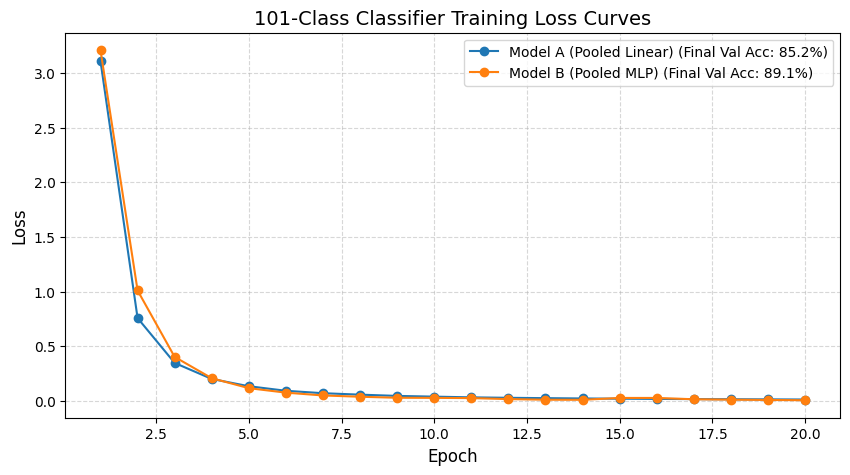

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import random

# 1. Setup Dataloaders
BATCH_SIZE = 32
train_dataset = TensorDataset(X_train_101, y_train_101)
test_dataset = TensorDataset(X_test_101, y_test_101)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# 2. Instantiate 101-class models
EMBED_DIM = 1024
NUM_CLASSES = 101
EPOCHS = 20

models_101 = {
    "Model A (Pooled Linear)": PooledLinearClassifier(EMBED_DIM, NUM_CLASSES).to("cuda"),
    "Model B (Pooled MLP)": PooledMLPClassifier(EMBED_DIM, hidden_dim=512, num_classes=NUM_CLASSES, dropout=0.3).to("cuda")
}

# 3. Training & Evaluation Pipeline
loss_histories = {name: [] for name in models_101}
final_accuracies = {}

for name, model_inst in models_101.items():
    optimizer = optim.AdamW(model_inst.parameters(), lr=1e-3, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()

    print(f"\n--- Training {name} on 101 Classes ---")
    for epoch in range(EPOCHS):
        model_inst.train()
        total_loss, correct, total = 0.0, 0, 0
        for inputs, targets in train_loader:
            inputs, targets = inputs.to("cuda"), targets.to("cuda")

            optimizer.zero_grad()
            outputs = model_inst(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()

        epoch_loss = total_loss / total
        train_acc = 100. * correct / total
        loss_histories[name].append(epoch_loss)

        # Evaluate on Test Set
        model_inst.eval()
        val_correct, val_total = 0, 0
        with torch.no_grad():
            for inputs, targets in test_loader:
                inputs, targets = inputs.to("cuda"), targets.to("cuda")
                outputs = model_inst(inputs)
                _, predicted = outputs.max(1)
                val_total += targets.size(0)
                val_correct += predicted.eq(targets).sum().item()

        val_acc = 100. * val_correct / val_total
        if (epoch + 1) % 5 == 0 or epoch == EPOCHS - 1:
            print(f"Epoch {epoch+1:02d}/{EPOCHS} | Loss: {epoch_loss:.4f} | Train Acc: {train_acc:.1f}% | Val Acc: {val_acc:.1f}%")

    final_accuracies[name] = val_acc

# 4. Plot Loss Curves
plt.figure(figsize=(10, 5))
for name, losses in loss_histories.items():
    plt.plot(range(1, EPOCHS + 1), losses, marker='o', label=f"{name} (Final Val Acc: {final_accuracies[name]:.1f}%)")
plt.title("101-Class Classifier Training Loss Curves", fontsize=14)
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

In [ ]:
# 5. Visualize a Random Test Inference
# Get index mappings for labels
idx_to_class_101 = {v: k for k, v in class_to_idx_101.items()}

# Select a random sample index from the test partition
rand_test_idx = random.choice(test_idx_101)
video_path = all_video_info[rand_test_idx]['path']
ground_truth_idx = all_video_info[rand_test_idx]['label']
ground_truth_class = idx_to_class_101[ground_truth_idx]

# Load 5 representative frames from video to display
loaded_frames = load_video(video_path, max_frames=5, target_size=(256, 256))

# Run prediction
sample_feature = X_all_101[rand_test_idx].unsqueeze(0).to("cuda") # (1, 1024)

predictions = {}
for name, model_inst in models_101.items():
    model_inst.eval()
    with torch.no_grad():
        logits = model_inst(sample_feature)
        probs = torch.softmax(logits, dim=1)
        conf, pred_class_idx = torch.max(probs, dim=1)
        predictions[name] = (idx_to_class_101[pred_class_idx.item()], conf.item() * 100)

# Plotting
fig, axes = plt.subplots(1, 5, figsize=(15, 4))
for idx, img in enumerate(loaded_frames):
    axes[idx].imshow(img)
    axes[idx].axis("off")
    if idx == 2:
        axes[idx].set_title(f"Test Video: {os.path.basename(video_path)}", fontsize=11, pad=10)

summary_text = f"Ground Truth: {ground_truth_class}\n"
for name, (pred, conf) in predictions.items():
    summary_text += f"{name}: Pred -> {pred} ({conf:.1f}% confidence)\n"

plt.figtext(0.5, -0.15, summary_text, wrap=True, horizontalalignment='center', fontsize=12, bbox=dict(facecolor='whitesmoke', alpha=0.8, boxstyle='round,pad=1'))
plt.tight_layout()
plt.show()

In [ ]:
!pip install -q yt-dlp

In [ ]:
import yt_dlp


yt_urls = {
    "surfing":"https://www.youtube.com/shorts/IiPk1VmKJTc",
    "sky_diving":"https://www.youtube.com/shorts/pyx07ZXDxEc",
    "ice_dancing":"https://www.youtube.com/shorts/N8xPS1d1FPc",
    "tennis_swing":"https://www.youtube.com/shorts/Esy-Uv1tt9o",
    "playing_guitar":"https://www.youtube.com/shorts/1z8c1NdNFbk",
    "drumming":"https://www.youtube.com/shorts/WkcomcZ8Z14",
}

for yt in yt_urls:
  print(yt)

surfing
sky_diving
ice_dancing
tennis_swing
playing_guitar
drumming


In [ ]:
import yt_dlp

yt_urls = {
    # "surfing":"https://www.youtube.com/shorts/IiPk1VmKJTc"
    # "sky_diving":"https://www.youtube.com/shorts/pyx07ZXDxEc",
    "ice_dancing":"https://www.youtube.com/shorts/N8xPS1d1FPc",
    "tennis_swing":"https://www.youtube.com/shorts/Esy-Uv1tt9o",
    "playing_guitar":"https://www.youtube.com/shorts/1z8c1NdNFbk",
    "drumming":"https://www.youtube.com/shorts/WkcomcZ8Z14",
}

for yt in yt_urls:
  ydl_opts = {
      'format': 'mp4/best',
      'outtmpl': f'{yt}.mp4',
      'extractor_args': {
          'youtube': {
              'player_client': ['ios', 'android', 'tv']
          }
      }
  }

  with yt_dlp.YoutubeDL(ydl_opts) as ydl:
      ydl.download([yt_urls[yt]])

In [ ]:

import os
import shutil
import subprocess
import tempfile
from pathlib import Path

import cv2
import numpy as np
import torch


def _get_model_device(model):
    """Resolve the model's current execution device."""
    try:
        return next(model.parameters()).device
    except StopIteration:
        return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def _draw_translucent_panel(frame, x1, y1, x2, y2, alpha=0.78):
    """Draw a dark translucent panel without obscuring the video."""
    h, w = frame.shape[:2]

    x1, x2 = max(0, x1), min(w, x2)
    y1, y2 = max(0, y1), min(h, y2)

    if x2 <= x1 or y2 <= y1:
        return

    roi = frame[y1:y2, x1:x2]
    panel = np.zeros_like(roi)
    panel[:] = (17, 24, 39)  # Dark navy in BGR

    cv2.addWeighted(panel, alpha, roi, 1 - alpha, 0, roi)

    # Teal accent border
    cv2.rectangle(
        frame,
        (x1, y1),
        (x2 - 1, y2 - 1),
        (190, 210, 45),
        2,
        cv2.LINE_AA
    )


def _draw_action_overlay(
    frame,
    action,
    confidence,
    frame_index,
    total_frames,
    fps
):
    """Render a professional action-recognition dashboard."""

    height, width = frame.shape[:2]

    # Improved responsive scaling for high resolution videos
    scale = max(width / 1000, 1.0)
    margin = int(width * 0.035)

    font = cv2.FONT_HERSHEY_SIMPLEX

    def put_text(text, x, y, size, color, thickness=2):
        cv2.putText(
            frame,
            str(text),
            (x, y),
            font,
            size * scale,
            color,
            max(2, int(thickness * scale)),
            cv2.LINE_AA
        )

    # Color palette (BGR)
    white = (245, 248, 255)
    muted = (175, 190, 210)
    teal = (190, 210, 45)
    dark = (17, 24, 39)

    # -----------------------------------------------------
    # TOP: PREDICTION RESULTS (Moved to Top & Made Larger)
    # -----------------------------------------------------
    card_h = int(height * 0.22)
    card_y = margin

    _draw_translucent_panel(
        frame,
        margin,
        card_y,
        width - margin,
        card_y + card_h
    )

    left = margin + int(width * 0.025)

    put_text(
        "DETECTED ACTION",
        left,
        card_y + int(card_h * 0.25),
        0.65,
        teal,
        2.5
    )

    # Main action label with adaptive scale
    max_label_length = 25
    display_action = str(action).replace("_", " ").upper()

    if len(display_action) > max_label_length:
        display_action = display_action[:max_label_length - 3] + "..."

    put_text(
        display_action,
        left,
        card_y + int(card_h * 0.58),
        1.35,
        white,
        3.5
    )

    # Confidence percentage
    confidence = float(np.clip(confidence, 0, 100))

    put_text(
        f"{confidence:.1f}% CONFIDENCE",
        left,
        card_y + int(card_h * 0.80),
        0.68,
        teal,
        2.5
    )

    # Confidence progress bar
    bar_x = left
    bar_y = card_y + int(card_h * 0.88)
    bar_w = int(width * 0.45)
    bar_h = max(8, int(height * 0.012))

    cv2.rectangle(
        frame,
        (bar_x, bar_y),
        (bar_x + bar_w, bar_y + bar_h),
        (65, 75, 90),
        -1
    )

    cv2.rectangle(
        frame,
        (bar_x, bar_y),
        (bar_x + int(bar_w * confidence / 100), bar_y + bar_h),
        teal,
        -1
    )

    # Video Analysis stats positioned on the right side of the card
    right_x = width - margin - int(width * 0.22)

    put_text(
        "VIDEO ANALYSIS",
        right_x,
        card_y + int(card_h * 0.40),
        0.55,
        muted,
        2
    )

    put_text(
        f"{frame_index + 1}/{total_frames}",
        right_x,
        card_y + int(card_h * 0.59),
        0.75,
        white,
        2.5
    )

    put_text(
        f"{fps:.1f} FPS",
        right_x,
        card_y + int(card_h * 0.77),
        0.55,
        muted,
        2
    )

    # -----------------------------------------------------
    # BOTTOM: MODEL IDENTIFICATION (Moved to Bottom Panel)
    # -----------------------------------------------------
    header_h = int(height * 0.115)
    header_y = height - header_h - margin

    _draw_translucent_panel(
        frame,
        margin,
        header_y,
        width - margin,
        height - margin
    )

    accent_w = max(5, int(width * 0.006))

    cv2.rectangle(
        frame,
        (margin, header_y),
        (margin + accent_w, height - margin),
        teal,
        -1
    )

    put_text(
        "AI ACTION RECOGNITION",
        margin + int(width * 0.025),
        header_y + int(header_h * 0.42),
        0.85,
        teal,
        2.5
    )

    put_text(
        "V-JEPA2  |  POOLED MLP CLASSIFIER",
        margin + int(width * 0.025),
        header_y + int(header_h * 0.76),
        0.58,
        white,
        1.5
    )

    # Status indicator
    status_x = width - margin - int(width * 0.22)

    cv2.circle(
        frame,
        (status_x, header_y + header_h // 2),
        max(6, int(8 * scale)),
        teal,
        -1
    )

    put_text(
        "ACTIVE",
        status_x + int(18 * scale),
        header_y + header_h // 2 + int(6 * scale),
        0.55,
        white,
        2
    )

    # -----------------------------
    # BOTTOM EDGE: VIDEO PROGRESS
    # -----------------------------
    progress = min(
        1.0,
        (frame_index + 1) / max(total_frames, 1)
    )

    cv2.rectangle(
        frame,
        (0, height - max(6, int(height * 0.006))),
        (int(width * progress), height),
        teal,
        -1
    )

    return frame


def _mux_audio(
    silent_video_path,
    original_video_path,
    output_video_path,
    duration,
    sound_path=None
):
    """
    Add audio only after visual processing is complete.

    If sound_path is provided, use it as background audio.
    Otherwise, preserve the original video's audio if available.
    """

    ffmpeg = shutil.which("ffmpeg")

    if ffmpeg is None:
        raise RuntimeError(
            "FFmpeg is required for audio muxing. "
            "Install FFmpeg and ensure it is available in PATH."
        )

    command = [ffmpeg, "-y", "-i", silent_video_path]

    if sound_path is not None:
        if not os.path.isfile(sound_path):
            raise FileNotFoundError(
                f"Sound file not found: {sound_path}"
            )

        # Loop the soundtrack if it is shorter than the video.
        command.extend([
            "-stream_loop", "-1",
            "-i", sound_path
        ])

        audio_input = "1:a:0"

    else:
        # Use the original source audio.
        command.extend(["-i", original_video_path])
        audio_input = "1:a:0"

    command.extend([
        "-map", "0:v:0",
        "-map", f"{audio_input}?",
        "-c:v", "copy",
        "-c:a", "aac",
        "-b:a", "192k",
        "-t", f"{duration:.4f}",
        "-movflags", "+faststart",
        "-shortest",
        output_video_path
    ])

    subprocess.run(
        command,
        check=True,
        capture_output=True,
        text=True
    )


def process_full_video_with_predictions(
    input_video_path,
    output_video_path,
    sound_path=None,
    max_seconds=6.0,
    chunk_size=32,
    target_size=(256, 256)
):
    """
    Complete action-recognition video pipeline.

    Stage 1: Process at most max_seconds of the input.
    Stage 2: Extract V-JEPA2 features in chunks.
    Stage 3: Classify using the trained Pooled MLP.
    Stage 4: Apply professional visual overlays.
    Stage 5: Add background audio or preserve source audio.

    Existing global objects:
        model
        processor
        models_101
        idx_to_class_101
    """

    input_video_path = str(input_video_path)
    output_video_path = str(output_video_path)

    if not os.path.isfile(input_video_path):
        raise FileNotFoundError(input_video_path)

    if max_seconds <= 0 or chunk_size <= 0:
        raise ValueError("max_seconds and chunk_size must be positive.")

    output_dir = os.path.dirname(
        os.path.abspath(output_video_path)
    )
    os.makedirs(output_dir, exist_ok=True)

    # -----------------------------
    # STAGE 1: VIDEO TRIMMING
    # -----------------------------

    cap = cv2.VideoCapture(input_video_path)

    if not cap.isOpened():
        raise RuntimeError("Unable to open input video.")

    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    if not np.isfinite(fps) or fps <= 0:
        cap.release()
        raise ValueError("Invalid video FPS.")

    max_frames = max(1, int(round(fps * max_seconds)))

    reported_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    total_frames = min(
        max_frames,
        reported_frames if reported_frames > 0 else max_frames
    )

    print("\n========== VIDEO PROCESSING ==========")
    print(f"Input: {input_video_path}")
    print(f"Resolution: {width}x{height}")
    print(f"FPS: {fps:.2f}")
    print(f"Maximum duration: {max_seconds:.2f}s")
    print(f"Frames to process: {total_frames}")

    if width <= 0 or height <= 0:
        cap.release()
        raise ValueError("Invalid video dimensions.")

    # -----------------------------
    # MODEL INITIALIZATION
    # -----------------------------

    model.eval()

    classifier = models_101["Model B (Pooled MLP)"]
    classifier.eval()

    device = _get_model_device(model)

    # Temporary video contains annotated frames without audio.
    temp_fd, silent_video_path = tempfile.mkstemp(
        suffix=".mp4",
        dir=output_dir
    )
    os.close(temp_fd)

    writer = None
    frames_written = 0

    try:
        fourcc = cv2.VideoWriter_fourcc(*"mp4v")

        writer = cv2.VideoWriter(
            silent_video_path,
            fourcc,
            fps,
            (width, height)
        )

        if not writer.isOpened():
            raise RuntimeError("Unable to initialize video writer.")

        # -----------------------------
        # STAGE 2: CHUNK INFERENCE
        # -----------------------------

        frame_index = 0

        while frame_index < total_frames:

            # Load only one chunk into memory.
            chunk_frames = []

            frames_to_read = min(
                chunk_size,
                total_frames - frame_index
            )

            for _ in range(frames_to_read):
                ret, frame = cap.read()

                if not ret:
                    break

                chunk_frames.append(frame)

            if not chunk_frames:
                break

            actual_chunk_length = len(chunk_frames)

            # Pad final chunk for the model only.
            model_frames = list(chunk_frames)

            while len(model_frames) < chunk_size:
                model_frames.append(model_frames[-1])

            # -----------------------------
            # V-JEPA2 FEATURE EXTRACTION
            # -----------------------------

            vjepa_frames = []

            for frame in model_frames:
                resized = cv2.resize(
                    frame,
                    target_size,
                    interpolation=cv2.INTER_AREA
                )

                rgb = cv2.cvtColor(
                    resized,
                    cv2.COLOR_BGR2RGB
                )

                vjepa_frames.append(rgb)

            video_array = np.asarray(vjepa_frames)

            inputs = processor(
                videos=[video_array],
                return_tensors="pt"
            )

            inputs = inputs.to(device)

            # -----------------------------
            # CLASSIFICATION
            # -----------------------------

            with torch.inference_mode():

                outputs = model(**inputs)

                pooled_feat = outputs.last_hidden_state.mean(
                    dim=1
                )

                logits = classifier(pooled_feat)

                probs = torch.softmax(logits, dim=1)

                confidence, pred_idx = torch.max(
                    probs,
                    dim=1
                )

                pred_class = idx_to_class_101[
                    pred_idx.item()
                ]

                confidence_score = (
                    confidence.item() * 100
                )

            # -----------------------------
            # STAGE 3: VISUAL OVERLAY
            # -----------------------------

            for frame in chunk_frames:

                annotated_frame = _draw_action_overlay(
                    frame=frame,
                    action=pred_class,
                    confidence=confidence_score,
                    frame_index=frame_index,
                    total_frames=total_frames,
                    fps=fps
                )

                writer.write(annotated_frame)

                frame_index += 1
                frames_written += 1

            print(
                f"Processed {frames_written}/{total_frames} "
                f"frames | Action: {pred_class} | "
                f"Score: {confidence_score:.1f}%"
            )

        cap.release()
        cap = None

        writer.release()
        writer = None

        if frames_written == 0:
            raise RuntimeError("No frames were successfully processed.")

        actual_duration = frames_written / fps

        # -----------------------------
        # STAGE 4: AUDIO MUXING
        # -----------------------------

        print("\nAdding audio...")

        _mux_audio(
            silent_video_path=silent_video_path,
            original_video_path=input_video_path,
            output_video_path=output_video_path,
            duration=actual_duration,
            sound_path=sound_path
        )

        print("\n========== PROCESSING COMPLETE ==========")
        print(f"Output: {output_video_path}")
        print(f"Duration: {actual_duration:.2f}s")
        print(f"Frames: {frames_written}")
        print(f"Audio: {'Background soundtrack' if sound_path else 'Original audio'}")

        return output_video_path

    finally:
        if cap is not None:
            cap.release()

        if writer is not None:
            writer.release()

        if os.path.exists(silent_video_path):
            os.remove(silent_video_path)


In [ ]:
yt_urls

{'sky_diving': 'https://www.youtube.com/shorts/pyx07ZXDxEc',
 'ice_dancing': 'https://www.youtube.com/shorts/N8xPS1d1FPc',
 'tennis_swing': 'https://www.youtube.com/shorts/Esy-Uv1tt9o',
 'playing_guitar': 'https://www.youtube.com/shorts/1z8c1NdNFbk',
 'drumming': 'https://www.youtube.com/shorts/WkcomcZ8Z14'}

In [ ]:
import yt_dlp

yt_url = "https://www.youtube.com/shorts/Dkyt_ayY6YE"
ydl_opts = {
    'format': 'mp4/best',
    'outtmpl': 'horse_riding.mp4',
}

with yt_dlp.YoutubeDL(ydl_opts) as ydl:
    ydl.download([yt_url])

[youtube] Extracting URL: https://www.youtube.com/shorts/Dkyt_ayY6YE
[youtube] Dkyt_ayY6YE: Downloading webpage


[youtube] Dkyt_ayY6YE: Downloading visionos player API JSON
[youtube] Dkyt_ayY6YE: Downloading m3u8 information
[info] Dkyt_ayY6YE: Downloading 1 format(s): 398
[download] Destination: horse_riding.mp4
[download] 100% of    1.52MiB in 00:00:00 at 16.22MiB/s  


In [ ]:
process_full_video_with_predictions(
    input_video_path="/content/surfing.mp4",
    output_video_path="/content/surfing_final.mp4",
    max_seconds=6,
    chunk_size=32
)


========== VIDEO PROCESSING ==========
Input: /content/surfing.mp4
Resolution: 2160x3840
FPS: 30.00
Maximum duration: 6.00s
Frames to process: 180
Processed 32/180 frames | Action: Surfing | Score: 99.1%
Processed 64/180 frames | Action: Surfing | Score: 99.6%
Processed 96/180 frames | Action: Surfing | Score: 98.3%
Processed 128/180 frames | Action: Surfing | Score: 90.8%
Processed 160/180 frames | Action: Surfing | Score: 88.1%
Processed 180/180 frames | Action: Surfing | Score: 99.6%

Adding audio...

========== PROCESSING COMPLETE ==========
Output: /content/surfing_final.mp4
Duration: 6.00s
Frames: 180
Audio: Original audio


'/content/surfing_final.mp4'

In [ ]:
import torch
from pathlib import Path

classes = [name for name, index in sorted(class_to_idx_101.items(), key=lambda pair: pair[1])]
checkpoint = {
    "state_dict": models_101["Model B (Pooled MLP)"].cpu().state_dict(),
    "classes": classes,
    "model_config": {
        "embed_dim": 1024,
        "hidden_dim": 512,
        "dropout": 0.3,
    },
}
Path("checkpoints").mkdir(exist_ok=True)
torch.save(checkpoint, "checkpoints/classifier.pt")